<a href="https://colab.research.google.com/github/mugalan/vibration-analysis/blob/main/answers-to-selected-assignments/Modeling_Simulation_Vehicle_Suspension_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Setting Up Python

In [1]:
import numpy as np
import scipy as sp
from scipy.integrate import odeint
import plotly.graph_objects as go

import sympy as sym
from sympy import symbols
from sympy import *

from sympy.physics.mechanics import dynamicsymbols, init_vprinting

# Vehicle Suspension System

Consider the small amplitude approximation of a vehicle suspension system shown below:

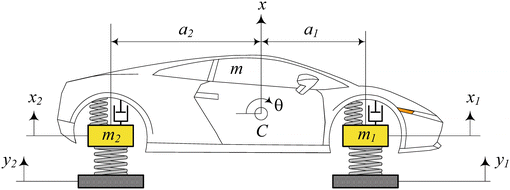

\begin{align}
m_1\ddot{y}_1&=-k_{t}y_1+k_{s}(x-a_1\theta-y_1)+c_{s}(\dot{x}-a_1\dot{\theta}-\dot{y}_1)\\
m_2\ddot{y}_2&=-k_{t}y_2+k_{s}(x+a_2\theta-y_2)+c_{s}(\dot{x}+a_2\dot{\theta}-\dot{y}_2)\\
m\ddot{x}&=-k_{s}(x+a_2\theta-y_2)-c_{s}(\dot{x}+a_2\dot{\theta}-\dot{y}_2)+-k_{s}(x-a_1\theta-y_1)-c_{s}(\dot{x}-a_1\dot{\theta}-\dot{y}_1)+f(t)\\
I\ddot{\theta}&=-a_2(k_{s}(x+a_2\theta-y_2)+c_{s}(\dot{x}+a_2\dot{\theta}-\dot{y}_2))+a_1(k_{s}(x-a_1\theta-y_1)+c_{s}(\dot{x}-a_1\dot{\theta}-\dot{y}_1))+T(t)
\end{align}

**Only the third equation above needs to be derived for the answer**

\begin{align}
m_1\ddot{y}_1+k_{t}y_1-k_{s}(x-a_1\theta-y_1)-c_{s}(\dot{x}-a_1\dot{\theta}-\dot{y}_1)&=0\\
m_2\ddot{y}_2+k_{t}y_2-k_{s}(x+a_2\theta-y_2)-c_{s}(\dot{x}+a_2\dot{\theta}-\dot{y}_2)&=0\\
m\ddot{x}+k_{s}(x+a_2\theta-y_2)+c_{s}(\dot{x}+a_2\dot{\theta}-\dot{y}_2)+k_{s}(x-a_1\theta-y_1)+c_{s}(\dot{x}-a_1\dot{\theta}-\dot{y}_1)&=f(t)\\
I\ddot{\theta}+a_2(k_{s}(x+a_2\theta-y_2)+c_{s}(\dot{x}+a_2\dot{\theta}-\dot{y}_2))-a_1(k_{s}(x-a_1\theta-y_1)+c_{s}(\dot{x}-a_1\dot{\theta}-\dot{y}_1))&=T(t)
\end{align}

\begin{align}
M\ddot{X}+C\dot{X}+KX&=F(t)
\end{align}

\begin{align}
X=\begin{bmatrix}y_1 & y_2 & x &\theta\end{bmatrix}^T,\:\:\:\:F(t)=\begin{bmatrix}0 & 0 & f(t) & T(t)\end{bmatrix}^T\\
M=\begin{bmatrix}
m_1 &0 & 0 & 0\\
0 & m_2 & 0 & 0\\
0 &0 & m & 0\\
0 &0 & 0 & I\\
\end{bmatrix},\:\:\:\:
K&=\begin{bmatrix}
(k_t+k_s) &0 & -k_s & a_1k_s\\
0 & (k_t+k_s) & -k_s & -a_2k_s\\
-k_s &-k_s & 2k_s & (a_2-a_1)k_s\\
a_1k_s &-a_2k_s & (a_2-a_1)k_s & (a_1^2+a_2^2)k_s\\
\end{bmatrix},\:\:\:\:\\
C=
\begin{bmatrix}
c_s &0 & -c_s & a_1c_s\\
0 & c_s & -c_s & -a_2c_s\\
-c_s &-c_s & 2c_s & (a_2-a_1)c_s\\
a_1c_s &-a_2c_s & (a_2-a_1)c_s & (a_1^2+a_2^2)c_s\\
\end{bmatrix}
\end{align}

For low damping $c_s\approx 0$ and the system behavior can be approximated by the solutions of the system
\begin{align}
\ddot{X}+\Omega X&=M^{-1}F
\end{align}
where $\Omega =M^{-1}K$.

In [2]:
m_0, a, m_1, m_2, k_t, k_s, c_s, m, I, a_1, a_2=symbols('m_0, a, m_1, m_2, k_t, k_s, c_s, m, I, a_1, a_2',real=True)

In [3]:
M=Matrix([[m_1,0,0,0],[0,m_2,0,0],[0,0,m,0],[0,0,0,I]])
K=Matrix([[k_t+k_s,0,-k_s,a_1*k_s],[0,k_t+k_s,-k_s,-a_2*k_s],[-k_s,-k_s,2*k_s,(a_2-a_1)*k_s],[a_1*k_s,-a_2*k_s,(a_2-a_1)*k_s,(a_1**2+a_2**2)*k_s]])
C=Matrix([[c_s,0,-c_s,a_1*c_s],[0,c_s,-c_s,-a_2*c_s],[-c_s,-c_s,2*c_s,(a_2-a_1)*c_s],[a_1*c_s,-a_2*c_s,(a_2-a_1)*c_s,(a_1**2+a_2**2)*c_s]])

In [4]:
Omega=M.inv()@K

###System when $m_1=m_2=m_0$ and $a_1=a_2=a$

In [6]:
[*Omega.subs({m_1:m_0, m_2:m_0, a_1:a, a_2:a}).subs({m_0:1, a:1, k_s:1, k_t:1}).eigenvals()]

[(I - sqrt(I**2 + 1) + 1)/I,
 (I + sqrt(I**2 + 1) + 1)/I,
 (m - sqrt(m**2 + 1) + 1)/m,
 (m + sqrt(m**2 + 1) + 1)/m]

In [ ]:
(sqrt(({k_s}*{m} + 2*{k_s}*{m_0} + {k_t}*{m} - sqrt({k_s}**2*{m}**2 + 4*{k_s}**2*{m}*{m_0} + 4*{k_s}**2*{m_0}**2 + 2*{k_s}*{k_t}*{m}**2 - 4*{k_s}*{k_t}*{m}*{m_0} + {k_t}**2*{m}**2))/(2*{m}*{m_0})),
 sqrt(({k_s}*{m} + 2*{k_s}*{m_0} + {k_t}*{m} + sqrt({k_s}**2*{m}**2 + 4*{k_s}**2*{m}*{m_0} + 4*{k_s}**2*{m_0}**2 + 2*{k_s}*{k_t}*{m}**2 - 4*{k_s}*{k_t}*{m}*{m_0} + {k_t}**2*{m}**2))/(2*{m}*{m_0})),
 sqrt(({I}*{k_s} + {I}*{k_t} + 2*{a}**2*{k_s}*{m_0} + sqrt({I}**2*{k_s}**2 + 2*{I}**2*{k_s}*{k_t} + {I}**2*{k_t}**2 + 4*{I}*{a}**2*{k_s}**2*{m_0} - 4*{I}*{a}**2*{k_s}*{k_t}*{m_0} + 4*{a}**4*{k_s}**2*{m_0}**2))/(2*{I}*{m_0})),
 sqrt(({I}*{k_s} + {I}*{k_t} + 2*{a}**2*{k_s}*{m_0} - sqrt({I}**2*{k_s}**2 + 2*{I}**2*{k_s}*{k_t} + {I}**2*{k_t}**2 + 4*{I}*{a}**2*{k_s}**2*{m_0} - 4*{I}*{a}**2*{k_s}*{k_t}*{m_0} + 4*{a}**4*{k_s}**2*{m_0}**2))/(2*{I}*{m_0})))

In [ ]:
Omega.subs({m_1:m_0,m_2:m_0, a_1:a, a_2:a}).subs({m_0:1,a:1,k_s:1,k_t:1,I:1,m:1}).eigenvals()

{2 - sqrt(2): 2, sqrt(2) + 2: 2}

In [ ]:
#40% given if the smaller number is given as the answer

###Simulation of the system dynamics

###Dynamic System form of the system

Let
\begin{align}
Y=\begin{bmatrix} y_1 & y_2 & x & \theta & \dot{y}_1 & \dot{y}_2 & \dot{x} & \dot{\theta}
\end{bmatrix}^T
\end{align}

The dynamic system for of the system is then

\begin{align}
\dot{Y}&=AY+Bu
\end{align}
where
\begin{align}
u=\begin{bmatrix} f(t) & T(t)
\end{bmatrix}^T\:\:\:\:\:
B=\begin{bmatrix} 0 &0 \\ 0 &0 \\0 &0 \\0 &0 \\0 &0 \\0 &0 \\\frac{1}{m} & 0\\0 &\frac{1}{I}
\end{bmatrix}
\end{align}
and
\begin{align}
A=\begin{bmatrix} 0_{4\times 4} & I_{4\times 4}\\
-M^{-1}K & -M^{-1}C
\end{bmatrix}
\end{align}

In [ ]:
X0=np.zeros(8)
dd=mgVF.simulateDySystem(10, 0.01, X0, np.array(A.subs({m_1:m_0,m_2:m_0, a_1:a, a_2:a}).subs({m_0:1,a:1,k_s:1,k_t:1, c_s:1,m:1, I:1})).astype(float),np.array(B.subs({m_0:1,a:1,k_s:1,k_t:1, c_s:1,m:1, I:1})).astype(float), [np.array([1,1]),0.1], 'xLabel', 'yLabel')

In [ ]:
B=Matrix(zeros(8,2))
B[6,0]=1/m
B[7,1]=1/I

In [ ]:
A=Matrix(zeros(8,8))
A[0:4,4:8]=Matrix(eye(4,4))
A[4:8,0:4]=-M.inv()@K
A[4:8,4:8]=-M.inv()@C